# Development of the learned weight matrix

**Julian Hoyer's experiment.** Every learned matrix in this notebook comes from
**explicitly executed gradient updates**, with $\lambda=1$, zero update noise,
and all 500 angles in every update. The direct run stops at **100,000 updates**.
No closed-form long-horizon matrices are plotted. The paper reference remains
the analytical ridge solution, computed on the same tuning curves with
regularization coefficient $10^{-8}$.

The first ten updates and successively spaced checkpoints are shown in original
and COM-sorted neuron order. The final figure compares only COM-sorted matrices
with the paper reference, labeling their relative Frobenius distances. The
layouts follow Clark et al.'s Figure 2a,b. All figures are embedded below.

Under this teaching condition, $x_i(\theta)=h_i(\theta)$. Changing $J$ changes
the recurrent prediction, not the full tuning curves. Circular COM is computed
from the firing-rate curve:

\[
\mu_i^{(n)}=\arg\!\left[\sum_\theta
\phi(x_i^{(n)}(\theta))e^{i\theta}\right]\pmod{2\pi}.
\]

It is recomputed at each displayed checkpoint and stays unchanged. Each step
here is one full-batch **learning update**, not one second of physical time;
somatic currents remain clamped during learning. The direct loop does not model
a continuous head-movement trajectory.

New direct checkpoints and restart files are stored in
`notebooks/weight_development_outputs/direct_full_batch/`. They are reused when
rerunning, provided the model and learning parameters agree. All previous
simulation outputs, `ring/` and `data/` remain unchanged.

In [1]:
import hashlib
import json
import time
import os
import sys
from io import BytesIO
from pathlib import Path

sys.dont_write_bytecode = True
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import numpy as np
import pandas as pd
import torch
from matplotlib.figure import Figure
from matplotlib.colors import Normalize
from IPython.display import Image, display
from PIL import Image as PILImage

here = Path.cwd().resolve()
parents = [here, *here.parents]
candidates = parents + [p / '.worktrees/local-learning' for p in parents]
ROOT = next(p for p in candidates if
            (p / 'notebooks/predictive_rule_outputs/full/model.npz').is_file())
sys.path.insert(0, str(ROOT))
from ring import data_driven, fn, style

SOURCE = ROOT / 'notebooks/predictive_rule_outputs/full'
OUT = ROOT / 'notebooks/weight_development_outputs'
OUT.mkdir(exist_ok=True)
config = json.loads((SOURCE / 'config.json').read_text())
with np.load(SOURCE / 'model.npz', allow_pickle=False) as model:
    H, Phi, J_paper = model['H'].copy(), model['Phi'].copy(), model['J_paper'].copy()
N, N_theta = config['N'], config['N_theta']
BATCH, ETA0, BETA = N_theta, config['eta0'], config['beta']
MAX_STEPS = 100_000
DEVICE, DTYPE = torch.device(config['device']), torch.float64
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.use_deterministic_algorithms(True)

def nonlin(x):
    return fn.nonlin_idealized(x, BETA)

def show_figure(fig, filename, dpi=145, preview_size=(1100, 1100)):
    path = OUT / filename
    fig.savefig(path, dpi=dpi)
    with PILImage.open(path) as image:
        preview = image.convert('RGB')
        preview.thumbnail(preview_size)
        preview = preview.quantize(colors=256)
        buffer = BytesIO()
        preview.save(buffer, format='PNG', optimize=True)
    display(Image(data=buffer.getvalue()))

print(f'Full-batch GD: lambda = 1; noise = 0; N = {N}; all {BATCH} angles per step; eta0 = {ETA0}.')
print('Generated figures and tables:', OUT)

Full-batch GD: lambda = 1; noise = 0; N = 1000; all 500 angles per step; eta0 = 0.5.
Generated figures and tables: /Users/julianhoyer/Documents/symmetries-continuous-attractors/.worktrees/local-learning/notebooks/weight_development_outputs


## Execute and checkpoint every full-batch update

Starting from $J=0$, every iteration explicitly computes
\[
J^{(n+1)}=\mathcal P_{\mathrm{off}}\!\left[
J^{(n)}+\frac{\eta_0}{NN_\theta}
(H^T-J^{(n)}\Phi^T)\Phi\right],
\]
where $\mathcal P_{\mathrm{off}}$ sets the diagonal to zero. No SVD or matrix
power replaces these updates. Plotted checkpoints are saved individually;
a separate restart snapshot is saved every 5,000 updates. A matching completed
run is loaded rather than repeated.

In [2]:
DIRECT = OUT / 'direct_full_batch'
DIRECT.mkdir(exist_ok=True)
CHECKPOINTS = sorted({n for n in list(range(1, 11)) +
                     [30, 100, 300, 1000, 3000, 10000, 30000, 100000]
                     if n <= MAX_STEPS} | {MAX_STEPS})
run_config = dict(
    model_sha256=hashlib.sha256((SOURCE / 'model.npz').read_bytes()).hexdigest(),
    N=N, N_theta=N_theta, eta0=ETA0, teaching_lambda=1, update_noise=0,
    dtype=str(DTYPE), algorithm='explicit full-batch GD; zero diagonal after each update',
)
config_path = DIRECT / 'run_config.json'
if config_path.exists() and json.loads(config_path.read_text()) != run_config:
    raise RuntimeError('Direct-run parameters changed. Move direct_full_batch aside before rerunning.')
config_path.write_text(json.dumps(run_config, indent=2)+'\n')

def checkpoint_path(step):
    return DIRECT / f'step_{step:010d}.npy'

def atomic_array(path, array):
    temporary = path.with_suffix('.tmp')
    with temporary.open('wb') as file:
        np.save(file, array, allow_pickle=False)
    os.replace(temporary, path)

def save_restart(matrix, step):
    temporary = DIRECT / 'restart.tmp'
    with temporary.open('wb') as file:
        np.savez(file, J=matrix, step=step)
    os.replace(temporary, DIRECT / 'restart.npz')

H_t = torch.as_tensor(H, dtype=DTYPE, device=DEVICE)
Phi_t = torch.as_tensor(Phi, dtype=DTYPE, device=DEVICE)
J = torch.zeros((N, N), dtype=DTYPE, device=DEVICE)
first_step = 0
if all(checkpoint_path(step).exists() for step in CHECKPOINTS):
    first_step = MAX_STEPS
    print(f'Loading previously executed full-batch checkpoints through {MAX_STEPS:,}.')
elif (DIRECT / 'restart.npz').exists():
    with np.load(DIRECT / 'restart.npz', allow_pickle=False) as state:
        candidate_step = int(state['step'])
        if candidate_step <= MAX_STEPS and all(checkpoint_path(n).exists() for n in CHECKPOINTS if n <= candidate_step):
            first_step = candidate_step
            J = torch.as_tensor(state['J'].copy(), dtype=DTYPE, device=DEVICE)
    print(f'Resuming direct full-batch learning after update {first_step:,}.')

started = time.perf_counter()
checkpoint_set = set(CHECKPOINTS)
with torch.no_grad():
    for step in range(first_step + 1, MAX_STEPS + 1):
        J.add_((H_t.T - J @ Phi_t.T) @ Phi_t, alpha=ETA0 / (N * N_theta))
        J.fill_diagonal_(0)
        if step in checkpoint_set:
            assert torch.isfinite(J).all()
            atomic_array(checkpoint_path(step), J.cpu().numpy())
        if step % 5000 == 0 or step == MAX_STEPS:
            save_restart(J.cpu().numpy(), step)
        if step % 1000 == 0 or step == MAX_STEPS:
            elapsed = time.perf_counter()-started
            progress = dict(completed_updates=step, target_updates=MAX_STEPS,
                            elapsed_seconds_this_execution=elapsed)
            (DIRECT / 'progress.json').write_text(json.dumps(progress, indent=2)+'\n')
            if step % 10000 == 0 or step == MAX_STEPS:
                print(f'Executed {step:,}/{MAX_STEPS:,} full-batch updates; '
                      f'elapsed {elapsed/60:.1f} min', flush=True)

snapshots = {0: np.zeros((N, N), dtype=np.float64)}
for step in CHECKPOINTS:
    snapshots[step] = np.load(checkpoint_path(step), allow_pickle=False)
STEPS = sorted(snapshots)
assert all(np.isfinite(matrix).all() and np.all(matrix.diagonal() == 0)
           for matrix in snapshots.values())
print('Directly executed checkpoints plotted:', STEPS)

Loading previously executed full-batch checkpoints through 100,000.
Directly executed checkpoints plotted: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 30, 100, 300, 1000, 3000, 10000, 30000, 100000]


## Recalculate COM and fix the color scale

The same permutation is applied to rows and columns. To match the original
figure's implementation, angular COMs are converted to angular-bin indices before
sorting. Both signs use one color scale across every checkpoint and the paper
reference. The limit is the larger 99th percentile of absolute weights in the
final learned matrix and paper matrix; rarer extremes saturate. No matrix is
normalized separately, so the growth of weight amplitude remains visible.

In [3]:
orders, coms = {}, {}
rows, com_rows = [], []
reference_com = data_driven.circular_com(Phi.T)
COLOR_LIMIT = max(float(np.quantile(np.abs(snapshots[STEPS[-1]]), .99)),
                  float(np.quantile(np.abs(J_paper), .99)))
NORM = Normalize(vmin=-COLOR_LIMIT, vmax=COLOR_LIMIT)
CMAP = style.DIVERGING_CMAP
paper_norm = np.linalg.norm(J_paper)
for step in STEPS:
    # Full theta-conditioned somatic responses at this checkpoint. They remain
    # H under lambda=1, even though the recurrent prediction changes with J.
    x_curves = H.copy()
    firing_curves = nonlin(x_curves)
    np.testing.assert_allclose(firing_curves, Phi, rtol=0, atol=0)
    coms[step] = data_driven.circular_com(firing_curves.T)
    _, orders[step] = data_driven.sort_weight_matrix(snapshots[step], firing_curves)
    change = np.rad2deg(np.angle(np.exp(1j * (coms[step] - reference_com))))
    matrix = snapshots[step]
    rows.append(dict(step=step, weight_rms=float(np.sqrt(np.mean(matrix**2))),
                     weight_norm=float(np.linalg.norm(matrix)),
                     relative_distance_from_paper=float(np.linalg.norm(matrix-J_paper)/paper_norm),
                     fraction_color_saturated=float(np.mean(np.abs(matrix) > COLOR_LIMIT)),
                     maximum_com_change_deg=float(np.max(np.abs(change)))))
    inverse_order = np.argsort(orders[step])
    com_rows.extend(dict(step=step, neuron=i+1, com_deg=float(np.rad2deg(coms[step][i])),
                         sorted_rank=int(inverse_order[i])+1) for i in range(N))

summary = pd.DataFrame(rows)
summary.to_csv(OUT / 'checkpoint_summary.csv', index=False)
pd.DataFrame(com_rows).to_csv(OUT / 'com_at_each_checkpoint.csv', index=False)
assert summary.maximum_com_change_deg.max() < 1e-10
assert all(np.array_equal(orders[step], orders[0]) for step in STEPS)
paper_sorted, paper_order = data_driven.sort_weight_matrix(J_paper, Phi)
assert np.array_equal(paper_order, orders[0])
print(f'COM recomputed at {len(STEPS)} checkpoints; maximum change = {summary.maximum_com_change_deg.max():.3g} degrees.')
print(f'Common color limits: {-COLOR_LIMIT:.6g} to {COLOR_LIMIT:.6g}.')
display(summary)

COM recomputed at 19 checkpoints; maximum change = 0 degrees.
Common color limits: -0.00854639 to 0.00854639.


,step,weight_rms,weight_norm,relative_distance_from_paper,fraction_color_saturated,maximum_com_change_deg
0,0,0.000000,0.000000,1.000000,0.000000,0.0
1,1,0.000319,0.318566,0.953618,0.000000,0.0
2,2,0.000488,0.488464,0.918373,0.000000,0.0
3,3,0.000603,0.603311,0.887191,0.000000,0.0
4,4,0.000699,0.698576,0.858603,0.000000,0.0
5,5,0.000786,0.786405,0.832188,0.000000,0.0
6,6,0.000870,0.870369,0.807727,0.000000,0.0
7,7,0.000951,0.951213,0.785047,0.000000,0.0
8,8,0.001029,1.028905,0.763998,0.000000,0.0
9,9,0.001103,1.103293,0.744440,0.000000,0.0


In [4]:
def matrix_at(step, sorted_by_com=False):
    if step == 'paper':
        return paper_sorted if sorted_by_com else J_paper
    matrix = snapshots[step]
    if sorted_by_com:
        order = orders[step]
        matrix = matrix[np.ix_(order, order)]
    return matrix

def draw_matrix(ax, matrix, title, sorted_by_com):
    image = ax.imshow(matrix, norm=NORM, cmap=CMAP, interpolation='nearest',
                      origin='upper', rasterized=True)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([0, N-1], ['1', str(N)])
    ax.set_yticks([0, N-1], ['1', str(N)])
    ax.tick_params(labelsize=7)
    ax.set_xlabel('Presynaptic COM rank' if sorted_by_com else 'Presynaptic neuron j', fontsize=8)
    ax.set_ylabel('Postsynaptic COM rank' if sorted_by_com else 'Postsynaptic neuron i', fontsize=8)
    ax.set_aspect('equal')
    return image

def grid_figure(steps, sorted_by_com, title, filename):
    columns = 4
    nrows = (len(steps) + columns - 1) // columns
    fig = Figure(figsize=(12, 3.05*nrows + .6), layout='constrained')
    axes = fig.subplots(nrows, columns, squeeze=False)
    for ax, step in zip(axes.flat, steps):
        label = 'Paper reference' if step == 'paper' else f'Step {step:,}'
        im = draw_matrix(ax, matrix_at(step, sorted_by_com), label, sorted_by_com)
    for ax in list(axes.flat)[len(steps):]:
        ax.set_visible(False)
    fig.colorbar(im, ax=list(axes.flat)[:len(steps)], shrink=.7, fraction=.025,
                 label='Jij (same scale at every step)', extend='both')
    fig.suptitle(title, fontsize=13)
    show_figure(fig, filename)

## First ten updates: original neuronal order

Step 0 is the zero initialization; steps 1–10 are explicitly executed updates.
The final panel is the paper reference on the same input realization and scale.

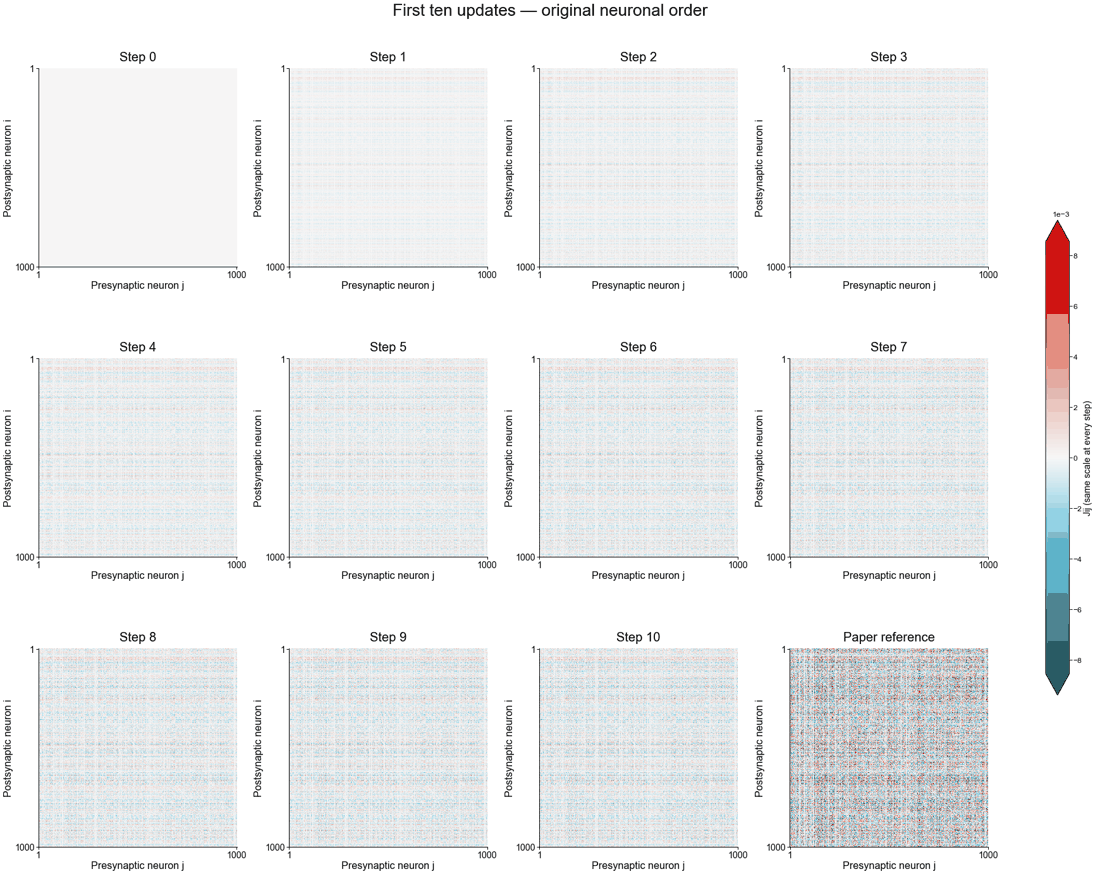

In [5]:
EARLY = list(range(11)) + ['paper']
grid_figure(EARLY, False, 'First ten updates — original neuronal order', 'first_10_original.png')

## First ten updates: COM-sorted order

COM is recalculated from the full clamped tuning curves at every checkpoint.
The order stays identical; changes in the panels are changes in J.

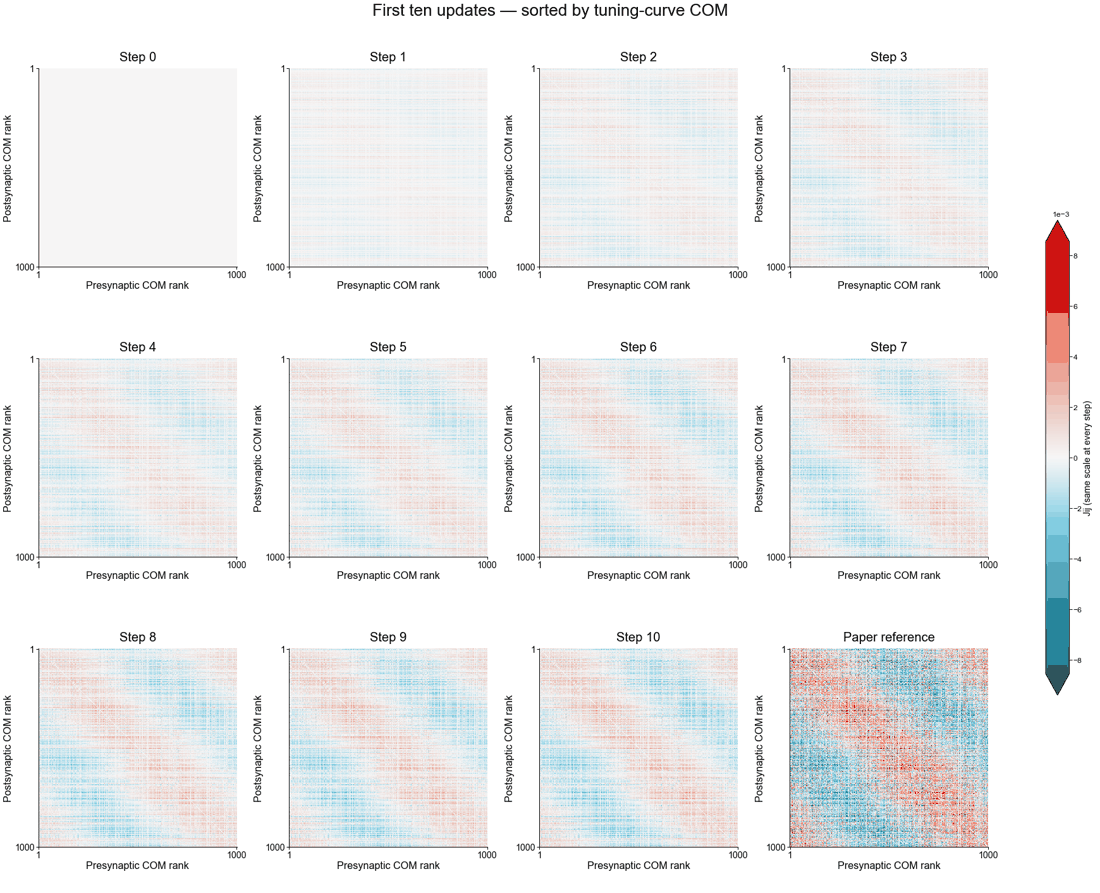

In [6]:
grid_figure(EARLY, True, 'First ten updates — sorted by tuning-curve COM', 'first_10_com_sorted.png')

## Later checkpoints: original neuronal order

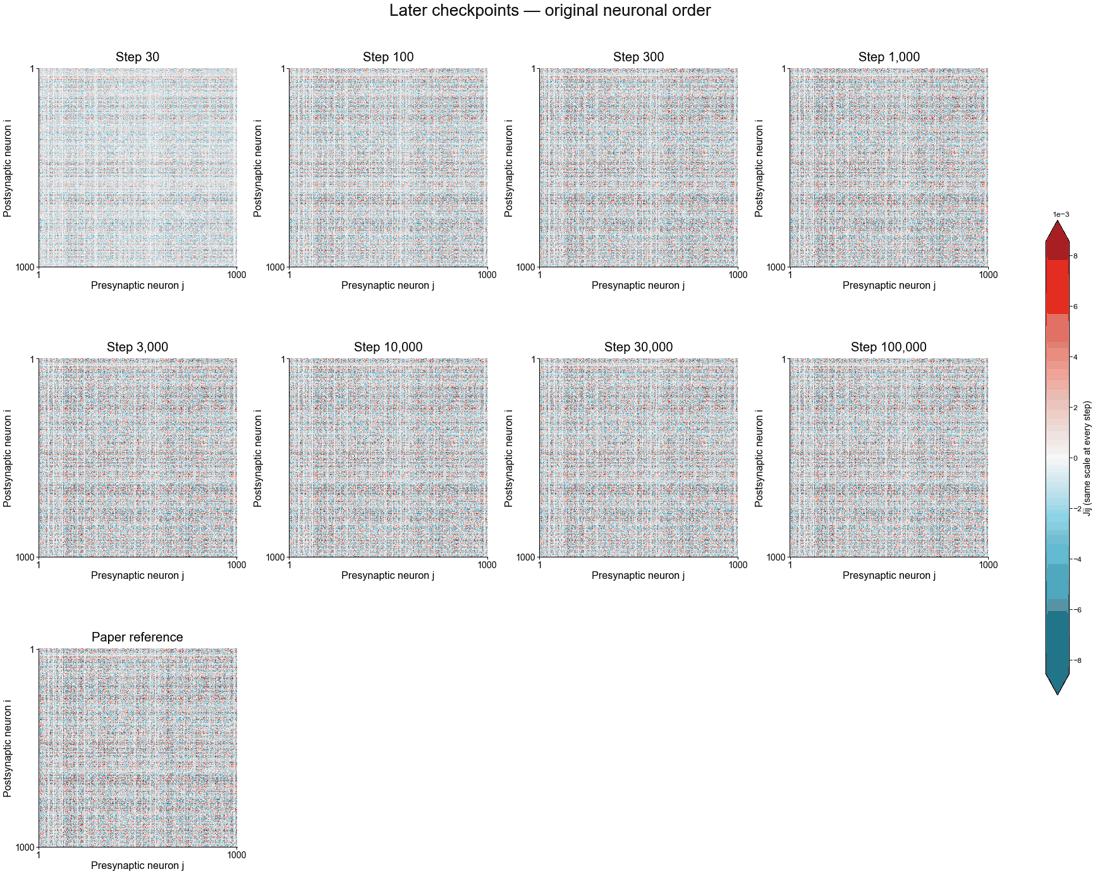

In [7]:
LATER = [step for step in STEPS if step > 10] + ['paper']
grid_figure(LATER, False, 'Later checkpoints — original neuronal order', 'later_original.png')

## Later checkpoints: COM-sorted order

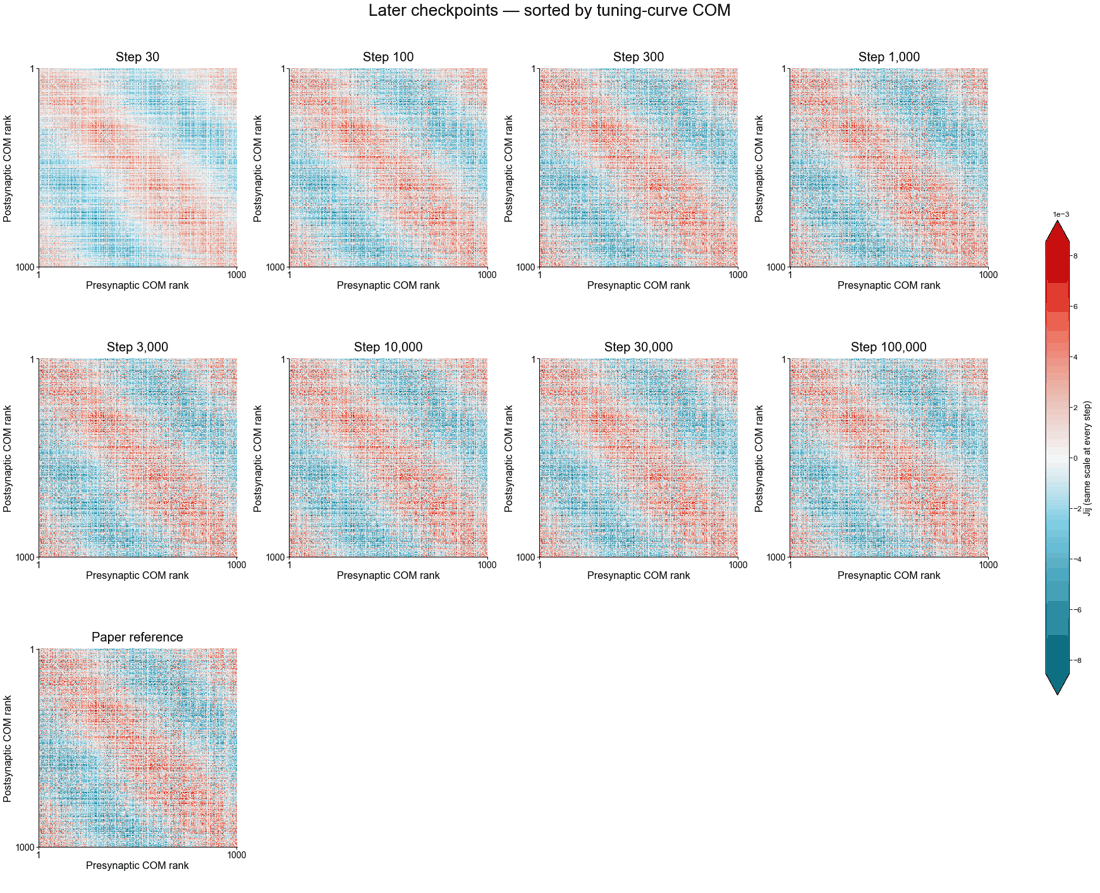

In [8]:
grid_figure(LATER, True, 'Later checkpoints — sorted by tuning-curve COM', 'later_com_sorted.png')

## Final directly learned matrix beside the paper reference

The columns correspond to Figure 2a,b: arbitrary order on the left and COM order
on the right. The upper row is the final directly executed full-batch checkpoint;
the lower row is the analytical paper reference.

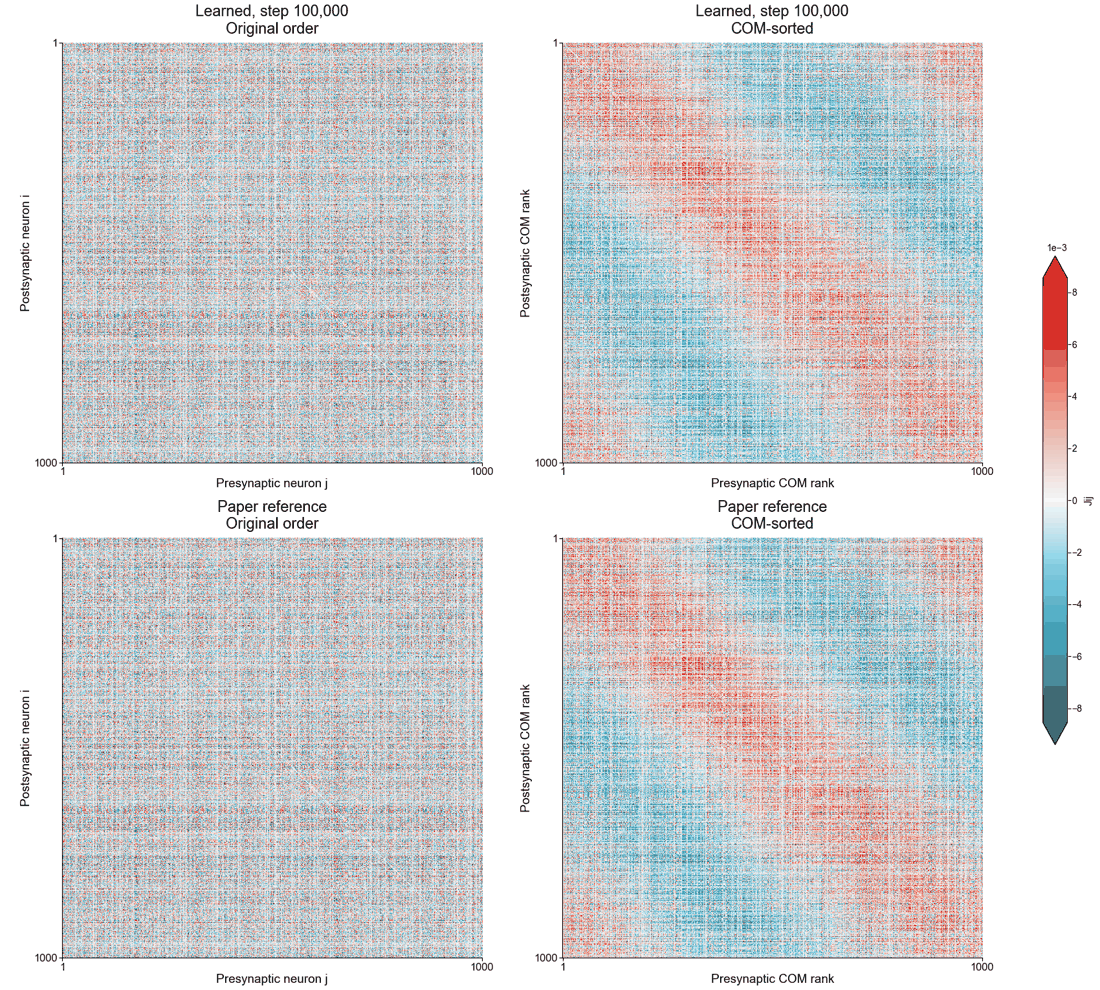

In [9]:
fig = Figure(figsize=(10, 9), layout='constrained')
axes = fig.subplots(2, 2)
for row, step in enumerate([STEPS[-1], 'paper']):
    name = f'Learned, step {step:,}' if step != 'paper' else 'Paper reference'
    for col, sorted_by_com in enumerate([False, True]):
        order_label = 'COM-sorted' if sorted_by_com else 'Original order'
        im = draw_matrix(axes[row, col], matrix_at(step, sorted_by_com),
                         f'{name}\n{order_label}', sorted_by_com)
fig.colorbar(im, ax=list(axes.flat), shrink=.7, fraction=.025, label='Jij', extend='both')
show_figure(fig, 'final_and_paper.png', dpi=170)

## Relative Frobenius distance to the paper reference

\[
\text{Relative Frobenius distance}
=\frac{\|J^{(n)}-J_{\mathrm{paper}}\|_F}{\|J_{\mathrm{paper}}\|_F}.
\]

Every learned matrix below is a saved checkpoint from the explicitly executed
full-batch loop. The maximum update count is 100,000. No matrices from the
closed-form long-horizon calculation are included.

In [10]:
COMPARISON_STEPS = [step for step in STEPS if step != 0]
comparison_panels = [('Direct full-batch GD', step, snapshots[step]) for step in COMPARISON_STEPS]
metric_rows = []
for training, step, matrix in comparison_panels:
    difference_norm = float(np.linalg.norm(J_paper-matrix))
    metric_rows.append(dict(training=training, step=step,
                            frobenius_norm_of_difference=difference_norm,
                            relative_frobenius_distance_to_paper=difference_norm/paper_norm))
difference_metrics = pd.DataFrame(metric_rows)
difference_metrics.to_csv(OUT / 'matrix_difference_metrics.csv', index=False)
display(difference_metrics)
assert difference_metrics.step.max() == MAX_STEPS
assert all(checkpoint_path(int(step)).exists() for step in difference_metrics.step)

,training,step,frobenius_norm_of_difference,relative_frobenius_distance_to_paper
0,Direct full-batch GD,1,2.967919,0.953618
1,Direct full-batch GD,2,2.858226,0.918373
2,Direct full-batch GD,3,2.761178,0.887191
3,Direct full-batch GD,4,2.672206,0.858603
4,Direct full-batch GD,5,2.589996,0.832188
5,Direct full-batch GD,6,2.513865,0.807727
6,Direct full-batch GD,7,2.443280,0.785047
7,Direct full-batch GD,8,2.377768,0.763998
8,Direct full-batch GD,9,2.316899,0.744440
9,Direct full-batch GD,10,2.260277,0.726247


## COM-sorted differences from directly executed learning

Every panel shows $J_{\mathrm{paper}}-J_{\mathrm{learned}}^{(n)}$, with its
**relative Frobenius distance** above it. All panels use one full-batch learning
trajectory, the same COM permutation, and one fixed zero-centered color scale.

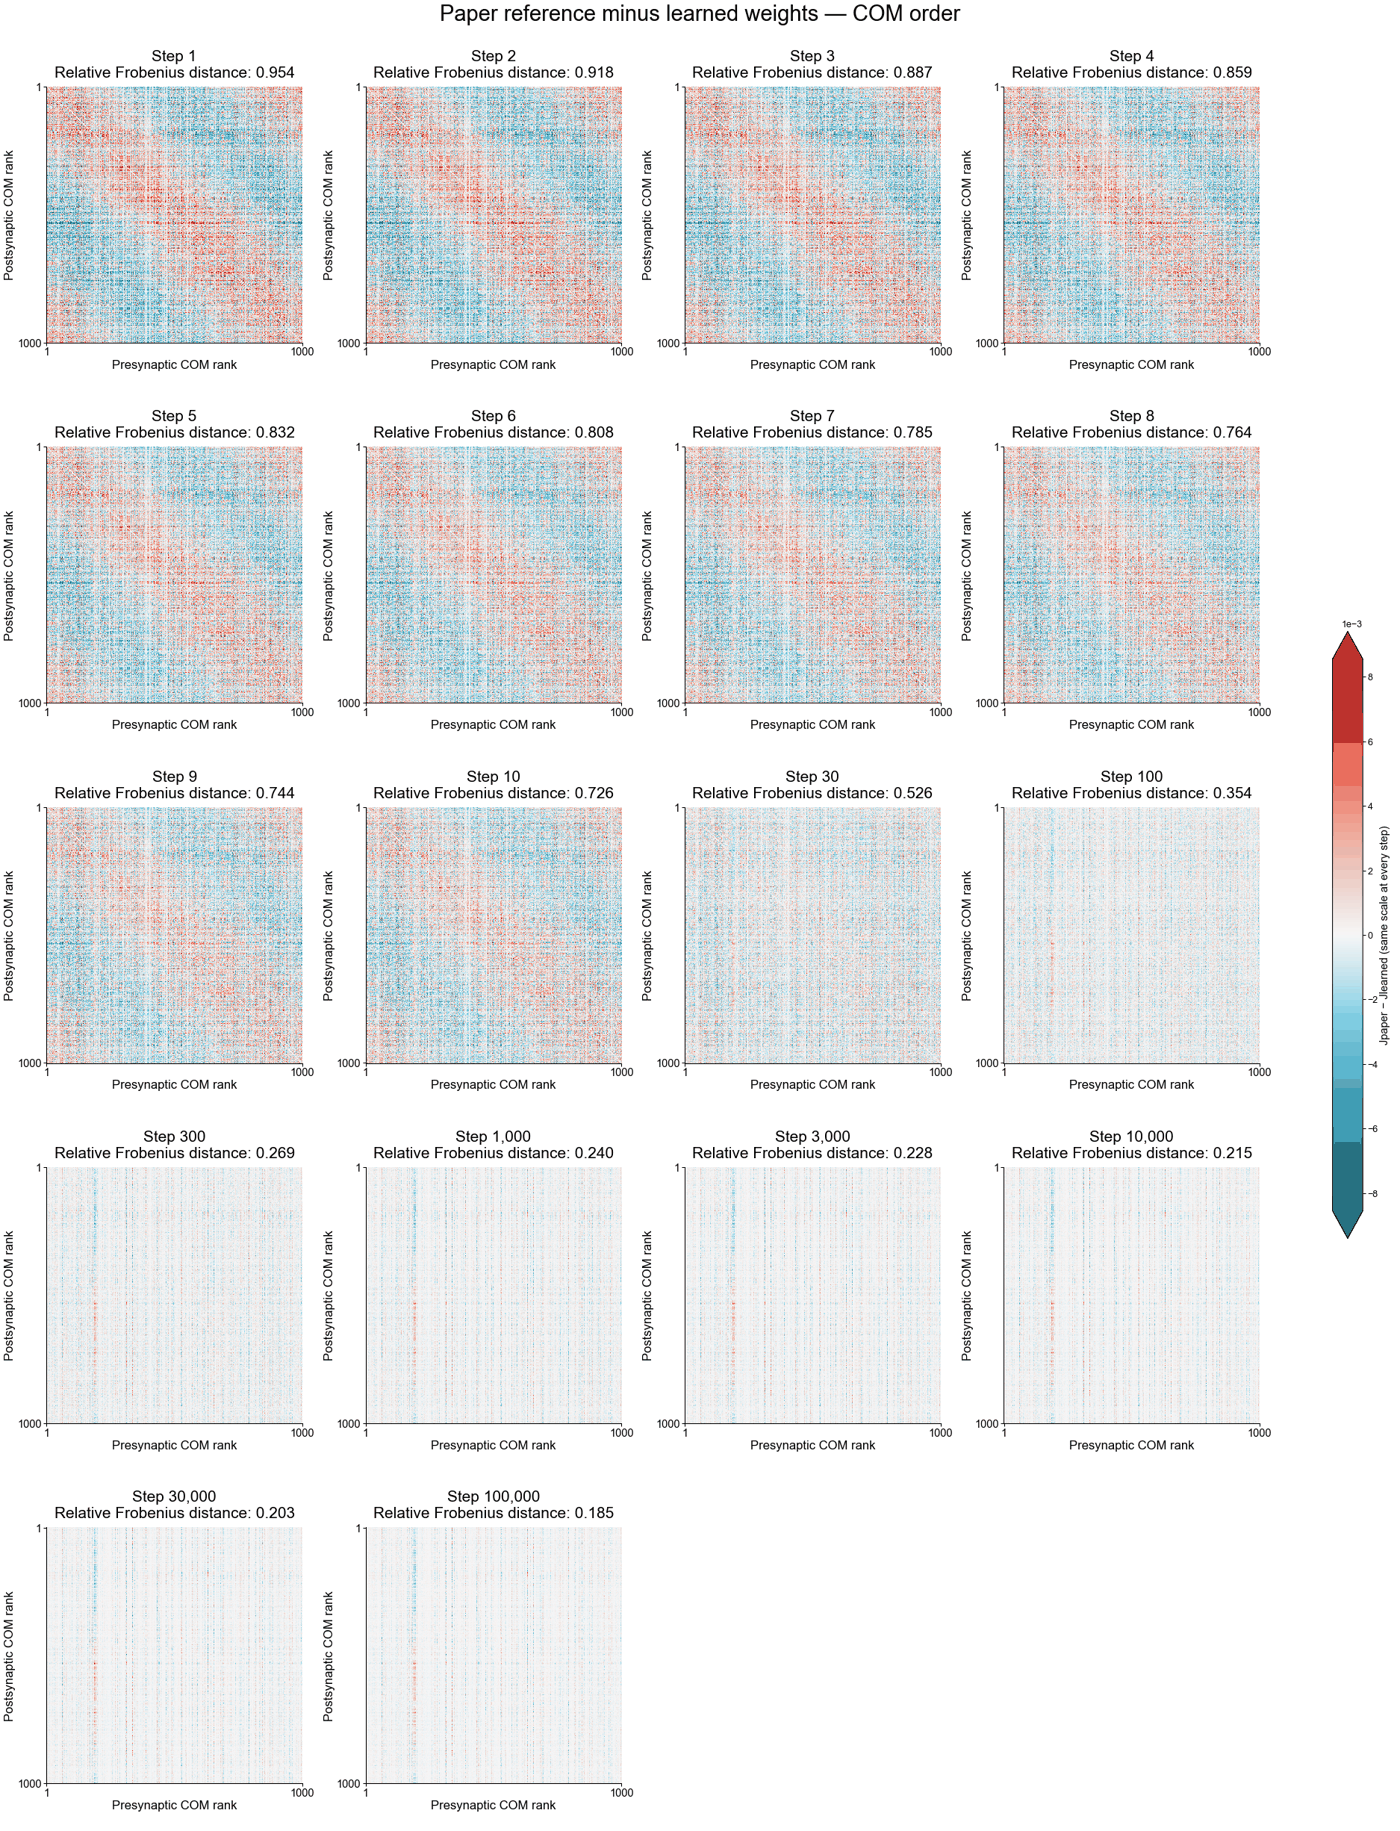

In [11]:
columns = 4
number_rows = (len(comparison_panels) + columns - 1) // columns
fig = Figure(figsize=(12.5, 3.15 * number_rows + .6), layout='constrained')
axes = fig.subplots(number_rows, columns, squeeze=False)
used_axes = []
for index, (training, step, matrix) in enumerate(comparison_panels):
    ax = axes.flat[index]
    difference = J_paper - matrix
    order = orders[0]
    sorted_difference = difference[np.ix_(order, order)]
    np.testing.assert_array_equal(sorted_difference,
                                  paper_sorted - matrix[np.ix_(order, order)])
    distance = difference_metrics.iloc[index].relative_frobenius_distance_to_paper
    step_label = f'{step:,}'
    title = f'Step {step_label}\nRelative Frobenius distance: {distance:.3f}'
    im = draw_matrix(ax, sorted_difference, title, sorted_by_com=True)
    used_axes.append(ax)
for ax in list(axes.flat)[len(comparison_panels):]:
    ax.set_visible(False)
fig.colorbar(im, ax=used_axes, shrink=.6, fraction=.025,
             label='Jpaper − Jlearned (same scale at every step)', extend='both')
fig.suptitle('Paper reference minus learned weights — COM order', fontsize=14)
show_figure(fig, 'paper_minus_learned_all_steps.png', dpi=150, preview_size=(1400, 2200))